# Discovering laws 2: From Kepler to Newton

*Learning path: discovering physical laws, part 2 of 4.* [Index](README.md) · Previous: [Kepler's third law](01-kepler.ipynb) · Next: [Mercury doesn't fit](03-mercury.ipynb)

Kepler's third law relates different planets. His first two laws are about a single orbit: it is an ellipse with the
Sun at one focus, and the line from the Sun to the planet sweeps out equal areas in equal times. Kepler found both in
Tycho Brahe's observations of Mars [1]. Newton then showed that all three follow from one force, pulling towards the
Sun with a strength proportional to $1/r^2$ [2]. In this lesson you will find all of this in a table of Mars
positions. You will learn

* how to change a table with `transform` (units, angles, $1/r$),
* how to give `discover` your own building blocks, such as $\cos\phi$,
* how `discover` finds a law involving a **rate of change**, written with a prime: $\phi'$ or $u''$,
* how the inverse-square law and the orbit equation drop out of the data.

## 1. A year of Mars

The table has one row every 28.6 days through one Martian year of 687 days. The columns are

1. $t$, the time in days since Mars passed its perihelion (its closest point to the Sun),
2. $\lambda$, Mars's direction seen from the Sun, in degrees, measured in the plane of the Earth's orbit from a fixed
   direction in the sky (the vernal equinox). It keeps counting past 360° so that it always increases.
3. $r$, the distance from the Sun in AU.

**Where the numbers come from.** They are computed from JPL's orbital elements for Mars [3], which summarise centuries
of real observations, and rounded to 0.01° and 0.0001 AU. They are not raw telescope readings, which would also
include the Earth's own motion; untangling that was Kepler's hardest problem, and we skip it.

In [1]:
mars = [0.0 336.06 1.3814; 28.6 354.17 1.3873; 57.2 372.00 1.4042; 85.9 389.27 1.4304; 114.5 405.85 1.4632; 143.1 421.65 1.4997; 171.7 436.70 1.5369; 200.4 451.04 1.5724; 229.0 464.78 1.6041; 257.6 478.03 1.6304; 286.2 490.91 1.6499; 314.9 503.54 1.6619; 343.5 516.06 1.6660; 372.1 528.57 1.6619; 400.7 541.20 1.6499; 429.4 554.08 1.6304; 458.0 567.33 1.6041; 486.6 581.07 1.5724; 515.2 595.42 1.5369; 543.9 610.46 1.4997; 572.5 626.26 1.4632; 601.1 642.84 1.4304; 629.7 660.12 1.4042; 658.4 677.94 1.3873];

To see the orbit, turn distance and direction into a position: $x = r\cos\lambda$, $y = r\sin\lambda$, with $\lambda$
converted from degrees to radians by multiplying with $\pi/180$. `scatter` takes the column names `[t lon r]` (three
columns, so three names) and then `[x y]` expressions in those names. The Sun is at the origin; both axes are in AU
and drawn to the same scale.

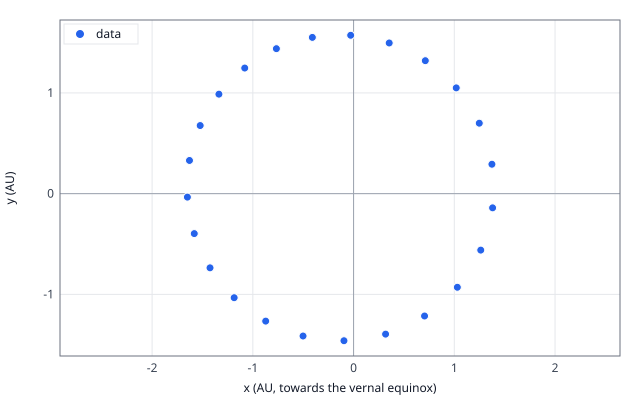

> `title`: A copy of plot p with a title or axis labels.

In [2]:
labels(scatter(mars, [t lon r], [r*cos(lon*pi/180) r*sin(lon*pi/180)]), "x (AU, towards the vernal equinox)", "y (AU)")

Notice that the dots are not evenly spaced around the orbit, although they are evenly spaced in time: Mars moves
faster near the Sun (on the right) and slower far away. We will come back to that in section 3.

## 2. The shape: an ellipse

How does the distance $r$ depend on the direction $\phi$? A natural first guess is a sum of waves:
$r = c_0 + c_1\cos\phi + c_2\sin\phi + \dots$. First we make a table with the angle in radians and the distance,
using `transform(data, [names], [new columns])`:

1. `mars`, the table to transform;
2. `[t lon r]`, names for its columns;
3. `[lon*pi/180 r]`, one expression per column of the new table, computed row by row.

In [3]:
polar = transform(mars, [t lon r], [lon*pi/180 r]);

Now `discover` with a third argument: a row of **candidate terms**. `discover` then looks for the fewest terms whose
weighted sum fits the data, trying every combination of one, two, three or four of them. This is the idea behind
SINDy, "sparse identification of nonlinear dynamics" [4]: offer many building blocks, keep only the few that matter.

In [4]:
discover(polar, [phi r], [1 cos(phi) sin(phi) cos(2*phi) sin(2*phi)])

[                                                   1.52;
                                     1.517-0.13*cos(phi);
                     0.0576*sin(phi)-0.13*cos(phi)+1.517;
 0.0576*sin(phi)-0.1298*cos(phi)-0.0049*sin(2*phi)+1.517]

> **discover**: $r$ in terms of $\phi$, 24 observations
>
> | # | complexity | rel. error | formula |
> |---|---|---|---|
> | 0 | 2 | 6.6% | $r = 1.52$ |
> | 1 | 8 | 2.7% | $r = 1.517 - 0.13 \, \cos\left(\phi\right)$ |
> | **2** ★ | 13 | 0.31% | **$r = 0.0576 \, \sin\left(\phi\right) - 0.13 \, \cos\left(\phi\right) + 1.517$** |
> | 3 | 20 | 0.21% | $r = 0.0576 \, \sin\left(\phi\right) - 0.1298 \, \cos\left(\phi\right) - 0.0049 \, \sin\left(2 \, \phi\right) + 1.517$ |
>
> ★ best: the simplest formula that predicts left-out rows at most twice as badly as the best one (leave-one-out test, at least two observations per fitted constant)

The best fit is off by 0.3%, ten times more than the rounding of the data, and adding $\cos 2\phi$ and $\sin 2\phi$
only helps a little. So $r$ is *not* a simple wave in $\phi$. Kepler tried this kind of curve for years.

Now try the reciprocal, $u = 1/r$:

In [5]:
orbit = transform(mars, [t lon r], [lon*pi/180 1/r]);
discover(orbit, [phi u], [1 cos(phi) sin(phi) cos(2*phi) sin(2*phi)])

[                                         0.651;
                         0.0563*cos(phi)+0.6602;
 0.0565102*cos(phi)-0.025094*sin(phi)+0.6620733]

> **discover**: $u$ in terms of $\phi$, 24 observations
>
> | # | complexity | rel. error | formula |
> |---|---|---|---|
> | 0 | 2 | 6.5% | $u = 0.651$ |
> | 1 | 8 | 2.7% | $u = 0.0563 \, \cos\left(\phi\right) + 0.6602$ |
> | **2** ★ | 13 | 0.0019% | **$u = 0.05651 \, \cos\left(\phi\right) - 0.025094 \, \sin\left(\phi\right) + 0.662073$** |
>
> ★ best: the simplest formula that predicts left-out rows at most twice as badly as the best one (leave-one-out test, at least two observations per fitted constant)

Now the fit is perfect to the rounding of the data (0.002%), with just three terms:

$$u = \frac{1}{r} = A + B\cos\phi + C\sin\phi .$$

A wave plus a constant can always be written as $A\,(1 + e\cos(\phi - \varpi))$, with $e = \sqrt{B^2 + C^2}/A$ and
$\varpi$ the angle where $u$ is largest, that is where Mars is closest to the Sun. And $r = 1/(A(1 + e\cos(\phi - \varpi)))$ is exactly the polar equation of an **ellipse** with the Sun at a focus, eccentricity $e$, and semi-major
axis $a = 1/(A(1-e^2))$ [5]. Kepler's first law. Let's compute the three numbers from the coefficients:

In [6]:
A = 0.6620733; B = 0.0565102; C = -0.025094;
ecc = eval(sqrt(B^2 + C^2)/A)
perihelion = eval(atan2(C, B)*180/pi + 360)
a = eval(1/(A*(1 - ecc^2)))

0.09339043759276303

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

336.0558391167732

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.5236961110946494

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Eccentricity 0.0934, perihelion at 336.06°, semi-major axis 1.5237 AU: JPL's elements for Mars are 0.09339, 336.06°
and 1.52371 AU [3]. Everything about the orbit's shape was in the data.

## 3. Equal areas: a law about a rate

Mars sped up near the Sun. How fast does its direction change? That is the **rate** $\phi' = d\phi/dt$, in radians per
day. We don't have it in the table, but `discover` can estimate it: write the name with a prime in the list of
columns, `[t phi' r]`. That means: the first column is time $t$; the second column holds $\phi$, and the quantity to
explain is its rate $\phi'$, estimated from each row and its neighbours (by fitting a smooth curve through five rows);
the third column is $r$.

In [7]:
k2 = transform(mars, [t lon r], [t lon*pi/180 r]);
discover(k2, [t phi' r])

[                            0.00858;
                        0.021141/r^2;
              0.021145/r^2-0.047/t^2;
 0.02121/r^2-4.3e-7*t/phi-0.0019*r/t]

> **discover**: $\phi'$ in terms of $t$, $\phi$, $r$, 20 observations ($\phi'$ estimated from neighbouring rows)
>
> | # | complexity | rel. error | formula |
> |---|---|---|---|
> | 0 | 2 | 11% | $\phi' = 0.00858$ |
> | **1** ★ | 5 | 0.12% | **$\phi' = \frac{0.021141}{r^{2}}$** |
> | 2 | 11 | 0.12% | $\phi' = \frac{0.021145}{r^{2}} - \frac{0.047}{t^{2}}$ |
> | 3 | 18 | 0.12% | $\phi' = \frac{0.02121}{r^{2}} - \frac{4.3\times 10^{-7} \, t}{\phi} - \frac{0.0019 \, r}{t}$ |
>
> ★ best: the simplest formula that predicts left-out rows at most twice as badly as the best one (leave-one-out test, at least two observations per fitted constant)
>
> power-law exponents fitted freely: t: 0.0048 ± 0.0048, phi: -0.017 ± 0.0184, r: -2.0119 ± 0.0118

The answer: $\phi' = 0.021141/r^2$, or

$$r^2\,\frac{d\phi}{dt} = h = 0.021141\ \text{AU}^2 \text{ per day}.$$

In a short time $dt$ the line from the Sun sweeps a thin triangle with sides $r$ and $r\,d\phi$, of area
$\tfrac12 r^2\,d\phi$. So the area swept per day is $h/2$, the same all around the orbit: **Kepler's second law**.
Physicists call $h$ the angular momentum per unit mass; it is constant because the force points straight at the Sun.

The note under the table shows the power law fitted with free exponents for all three columns: $t$ and $\phi$ get
exponents $0.005 \pm 0.005$ and $-0.02 \pm 0.02$, zero within the errors, so they don't matter; $r$ gets
$-2.01 \pm 0.01$.

## 4. Newton's inverse-square law

What force holds a planet in its orbit? For a nearly circular orbit of radius $a$ and period $T$, the speed is
$v = 2\pi a/T$ and the acceleration towards the centre is $g = v^2/a = 4\pi^2 a/T^2$. We can compute $g$ for every
planet from the table of lesson 1 and ask how it depends on distance:

In [8]:
planets = [0.3871 0.2408; 0.7233 0.6152; 1.000 1.000; 1.524 1.881; 5.203 11.86; 9.537 29.45; 19.19 84.02; 30.07 164.8];
pull = transform(planets, [a T], [a 4*pi^2*a/T^2]);
discover(pull, [r g])

[                       0.057;
                     39.5/r^2;
             4*pi^2/r^1.99976;
          39.493/r^2+0.000039;
          0.0013/r+39.489/r^2;
 0.0027/r+39.485/r^2-0.000049]

> **discover**: $g$ in terms of $r$, 8 observations
>
> | # | complexity | rel. error | formula |
> |---|---|---|---|
> | 0 | 2 | 86% | $g = 0.057$ |
> | **1** ★ | 5 | 0.054% | **$g = \frac{39.5}{r^{2}}$** |
> | 2 | 7 | 0.047% | $g = \frac{4 \, \pi^{2}}{r^{1.99976}}$ |
> | 3 | 8 | 0.045% | $g = \frac{39.493}{r^{2}} + 3.9\times 10^{-5}$ |
> | 4 | 11 | 0.042% | $g = \frac{0.0013}{r} + \frac{39.489}{r^{2}}$ |
> | 5 | 13 | 0.041% | $g = \frac{0.0027}{r} + \frac{39.485}{r^{2}} - 4.9\times 10^{-5}$ |
>
> ★ best: the simplest formula that predicts left-out rows at most twice as badly as the best one (leave-one-out test, at least two observations per fitted constant)
>
> power-law exponents fitted freely: r: -1.9998 ± 0.0001

$g = 39.5/r^2$: the pull of the Sun falls off as the **inverse square** of the distance. The axes of the next plot are
both logarithmic, so the straight line of slope $-2$ is the inverse-square law: horizontally the log of the distance in
AU, vertically the log of the acceleration in AU per year².

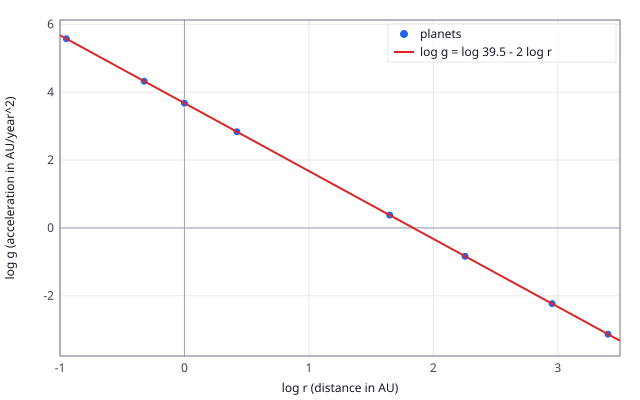

> `legend`: A copy of plot p with new names for its curves in the legend.

In [9]:
legend(labels(show(scatter(pull, [r g], [log(r) log(g)]), plot(log(39.5) - 2*x, x, -1, 3.5)), "log r  (distance in AU)", "log g  (acceleration in AU/year^2)"), "planets", "log g = log 39.5 - 2 log r")

The constant is the Sun's $GM$ in these units: $g = GM/r^2$. Combining with $g = 4\pi^2 a/T^2$ gives
$T^2 = 4\pi^2 a^3/GM$, and since $T = 1$ year when $a = 1$ AU, $GM_\odot = 4\pi^2 = 39.48$ AU³/year². `discover`
wrote 39.5 instead of $4\pi^2$, because with four-digit data both are within the uncertainty and it doesn't guess.
`check` can test the precise hypothesis, and fit a free constant $k$ for comparison:

In [10]:
check([4*pi^2/r^2, k/r^2], pull, [r g])

[4*pi^2/r^2;
   39.5/r^2]

> **check**: 2 formulas for $g$ against 8 observations
>
> | formula | fitted constants | rel. error | verdict |
> |---|---|---|---|
> | $g = \frac{4 \, \pi^{2}}{r^{2}}$ | none | 0.076% | within 0.14% |
> | $g = \frac{k}{r^{2}}$ | $k = 39.5 \pm 0.008$ | 0.054% | within 0.083% |

Both fit to better than 0.1%. The fitted $k = 39.50 \pm 0.01$ is within 0.06% of $4\pi^2 = 39.48$; the small
remainder is the rounding of the periods and the planets' own masses, which we met in lesson 1. Notice the division of
labour: the hypothesis $4\pi^2$ came from us, and the data could only confirm it.

## 5. The law of motion as an equation

So far each law described the orbit. Newton's insight was a law that *generates* orbits: a differential equation.
For orbits it is nicest in terms of $u = 1/r$ and the angle $\phi$ (see the [general relativity orbits
lesson](../general-relativity/05-orbits.ipynb) for the derivation): an inverse-square force gives the **Binet equation**

$$u'' + u = \frac{GM}{h^2}, \qquad u'' = \frac{d^2u}{d\phi^2}.$$

Can we find this equation in the data, without assuming it? We ask `discover` for $u''$, the second rate of change of
$u$ with respect to $\phi$, as a sum of powers of $u$. In `[phi u'']`, the first column $\phi$ is the variable we
differentiate by, and `u''` means: the second column holds $u$, explain its second derivative.

In [11]:
discover(orbit, [phi u''], [1 u u^2 u^3])

[  0.018;
 0.662-u]

> **discover**: $u''$ in terms of $\phi$, $u$, 20 observations ($u''$ estimated from neighbouring rows)
>
> | # | complexity | error | formula |
> |---|---|---|---|
> | 0 | 2 | 89% | $u'' = 0.018$ |
> | **1** ★ | 6 | 1.4% | **$u'' = 0.662 - u$** |
>
> ★ best: the simplest formula that predicts left-out rows at most twice as badly as the best one (leave-one-out test, at least two observations per fitted constant)

$u'' = 0.662 - u$, so $u'' + u = 0.662$: the Binet equation. Estimating a second derivative from rounded data costs
precision (the fit is "only" 1.4% good), yet the coefficient of $u$ came out as $-1.00$ and `discover` recognised it.

And the constant should be $GM/h^2$. We know both: $GM = 4\pi^2$ AU³/year² from section 4, and $h = 0.021141$ AU²/day
from section 3, which is $0.021141 \times 365.25$ AU²/year:

In [12]:
h = 0.021141*365.25;
eval(4*pi^2/h^2)

0.6621070848698718

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.6621, matching the 0.662 in the equation and the $A = 0.66207$ of the ellipse. Three separate fits, on three
different questions, tell one consistent story: Newton's gravity.

**A warning about building blocks.** We offered only powers of $u$, not $\cos\phi$. A force law shouldn't depend on
which direction in the sky the planet happens to be (space has no preferred direction), so terms in $\phi$ don't
belong in a *law*, although they did belong in the *description* of one orbit in section 2. Choosing the building
blocks is where physics enters; [part 3](03-mercury.ipynb) shows what goes wrong otherwise.

## Sources

Numbers in square brackets in the text refer to this list.

1. J. Kepler, *Astronomia Nova* (Heidelberg, 1609). English translation: *New Astronomy*, transl. W. H. Donahue,
   Cambridge University Press (1992).
2. I. Newton, *Philosophiæ Naturalis Principia Mathematica* (London, 1687), Book I, Propositions 11–13 and Book III.
3. E. M. Standish, *Keplerian Elements for Approximate Positions of the Major Planets*, JPL Solar System Dynamics,
   Table 1: Mars $a$ = 1.52371034 AU, $e$ = 0.09339410, longitude of perihelion 336.05637°,
   [ssd.jpl.nasa.gov/planets/approx_pos.html](https://ssd.jpl.nasa.gov/planets/approx_pos.html). Positions computed
   by solving Kepler's equation at 24 equally spaced times, ignoring the small tilt of Mars's orbit (1.85°).
4. S. L. Brunton, J. L. Proctor and J. N. Kutz, "Discovering governing equations from data by sparse identification of
   nonlinear dynamical systems", *PNAS* **113**, 3932–3937 (2016).
   [doi:10.1073/pnas.1517384113](https://doi.org/10.1073/pnas.1517384113)
5. H. Goldstein, C. Poole and J. Safko, *Classical Mechanics*, 3rd edition, Addison-Wesley (2002), sections 3.7–3.8.

Next: [Mercury doesn't fit](03-mercury.ipynb): a 43-arcsecond problem, and the term that solves it.